# Nutrition5k: resultados de los ViT puros

No entrena nada: lee los runs de `outputs/plain_vit/` (los escribe `02_experiments.ipynb` de esta carpeta) con las
funciones de `src/nutrition5k/results.py`. Elegir siempre por **validación** (`val_mean_pmae`); test se informa pero no
decide. `test_clean_mean_pmae` es el test oficial sin los platos de `data/nutrition5k/excluded_dishes.csv`.

In [1]:
import os
from pathlib import Path

if Path("/workspace").is_dir():  # RunPod
    # The clone made by 02_experiments.ipynb: outputs/ links to the volume and data/ holds the frames.
    os.chdir("/root/thesis-multimodal-health-ai")
elif Path.cwd().parent.name == "notebooks":
    os.chdir("../..")

import pandas as pd

from nutrition5k.results import (
    baseline_row, compare, cost, gallery, load_runs, seed_files, seed_groups, seed_spread, seed_table,
    seed_targets, select, steps, target_curves, target_table, test_metrics,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

FAMILY = "plain_vit"
SPLIT = "pilot"         # "full" o "pilot"
MODE = "complete"      # modo de frames a comparar

all_runs = load_runs([FAMILY], SPLIT, MODE)
assert len(all_runs), f"no runs of {FAMILY} in {SPLIT}; train them with 02_experiments.ipynb"
runs = select(all_runs)  # the recipe of the current runs; all_runs keeps every recipe
BASELINE = baseline_row(SPLIT)
print(f"{len(all_runs)} runs ({len(runs)} with the current recipe); baseline mean PMAE: "
      f"val {BASELINE['val_mean_pmae'].iloc[0]}, test {BASELINE['test_mean_pmae'].iloc[0]}")
runs

5 runs (5 with the current recipe); baseline mean PMAE: val 68.78185594884593, test 55.11396595533928


,run,path,family,backbone,recipe,unfreeze,heads,hidden,image_size,backbone_lr,seed,params_M,trainable_M,epochs_done,best_epoch,sec_per_epoch,gpu,gpu_memory_gb,status,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,val_total_mass_pmae,val_total_mass_mae,val_total_mass_rmse,val_total_mass_rsquared,val_total_calories_pmae,val_total_calories_mae,val_total_calories_rmse,val_total_calories_rsquared,val_total_fat_pmae,val_total_fat_mae,val_total_fat_rmse,val_total_fat_rsquared,val_total_carb_pmae,val_total_carb_mae,val_total_carb_rmse,val_total_carb_rsquared,val_total_protein_pmae,val_total_protein_mae,val_total_protein_rmse,val_total_protein_rsquared,test_total_mass_pmae,test_total_mass_mae,test_total_mass_rmse,test_total_mass_rsquared,test_total_calories_pmae,test_total_calories_mae,test_total_calories_rmse,test_total_calories_rsquared,test_total_fat_pmae,test_total_fat_mae,test_total_fat_rmse,test_total_fat_rsquared,test_total_carb_pmae,test_total_carb_mae,test_total_carb_rmse,test_total_carb_rsquared,test_total_protein_pmae,test_total_protein_mae,test_total_protein_rmse,test_total_protein_rsquared
1,deit_s-ft_all-single-h512-224-complete-pilot-f...,outputs/plain_vit/pilot/deit_s/deit_s-ft_all-s...,plain_vit,deit_s,fbn+clean,all,single,512,224,0.0001,0,21.995397,21.995397,3,2,13.266016,None,NaN,done,53.225851,63.548296,63.548296,39.323809,130.686127,169.944525,0.320511,32.055239,82.796725,90.109342,0.609439,95.335307,14.600667,16.571482,0.164381,34.339592,5.500657,6.426999,0.005921,65.075306,19.917222,21.408150,-0.103141,104.884615,120.748413,133.884885,-8.448671,43.760350,119.556681,145.191629,0.125899,70.919940,13.388311,16.333062,-0.127026,52.678836,7.136428,9.212699,-0.804607,45.497738,6.534667,8.367902,0.197522
3,dinov2_s-ft_0-single-h512-224-complete-pilot-f...,outputs/plain_vit/pilot/dinov2_s/dinov2_s-ft_0...,plain_vit,dinov2_s,fbn+clean,0,single,512,224,0.0001,0,21.959685,0.329733,3,2,16.143064,None,NaN,done,60.018036,52.026947,52.026947,61.317993,203.780131,241.859735,-0.376243,35.883918,92.685972,110.704634,0.410504,94.037742,14.401944,18.045066,0.009163,32.455327,5.198828,5.848072,0.176943,76.395202,23.381837,25.895876,-0.614113,37.146833,42.765291,47.157364,-0.172213,48.933529,133.690208,157.390033,-0.027148,76.961359,14.528814,18.308627,-0.416154,42.780169,5.795450,7.238837,-0.114157,54.312847,7.800747,9.988580,-0.143424
4,dinov2_s-ft_all-single-h512-224-complete-pilot...,outputs/plain_vit/pilot/dinov2_s/dinov2_s-ft_a...,plain_vit,dinov2_s,fbn+clean,all,single,512,224,0.0001,0,21.959685,21.959685,3,1,16.849267,None,NaN,done,61.857766,68.011651,68.011651,52.488135,174.435567,212.311577,-0.060511,44.428065,114.754982,151.027756,-0.097141,97.174648,14.882363,16.953484,0.125412,47.366370,7.587340,9.288386,-1.076275,67.831613,20.760829,21.241087,-0.085991,101.678848,117.057774,128.850420,-7.751436,47.358525,129.387177,160.108591,-0.062938,69.950133,13.205231,15.619382,-0.030686,71.592132,9.698621,11.965715,-2.044291,49.478618,7.106425,9.149269,0.040660
2,deit_t-ft_all-single-h512-224-complete-pilot-f...,outputs/plain_vit/pilot/deit_t/deit_t-ft_all-s...,plain_vit,deit_t,fbn+clean,all,single,512,224,0.0001,0,5.755845,5.755845,3,2,7.898613,None,NaN,done,62.873464,55.467740,55.467740,65.010437,216.051353,282.300973,-0.874963,55.368372,143.013125,155.014319,-0.155827,83.325218,12.761314,14.173590,0.388713,29.736556,4.763324,7.546179,-0.370435,80.926739,24.768778,28.331999,-0.932089,36.086108,41.544132,43.965896,-0.018919,59.526826,162.631922,204.743357,-0.738194,68.074650,12.851176,16.240418,-0.114277,54.647359,7.403105,8.482195,-0.529767,59.003758,8.474485,10.902727,-0.362292
0,deit_s-ft_0-single-h512-224-complete-pilot-fbn...,outputs/plain_vit/pilot/deit_s/deit_s-ft_0-sin...,plain_vit,deit_s,fbn+clean,0,single,512,224,0.0001,0,21.995397,0.329733,3,2,13.000169,None,NaN,done,68.068530,57.564285,57.564285,59.608833,198.100021,241.689450,-0.374306,58.943928,152.248568,153.542806,-0.133987,92.759171,14.206130,17.151857,0.104825,

## Etapa 1 (L1): arquitecturas (fine-tuning completo, cabeza `single`, 512, 224 px, lr del backbone 1e-4, semilla 0)

Resumen (`best_epoch` es la época con el menor `val_mean_pmae`, la que se guarda en `best.pt` y se evalúa), tabla de
validación con PMAE, MAE, RMSE y R² por objetivo (en verde el mejor de cada columna; MAE y RMSE en g o kcal), PMAE por
objetivo en barras y curvas de validación (el círculo grande marca la mejor época). La fila `baseline` es la línea
base de la media (predice la media de train para todos los platos) sobre la misma validación.

,run,status,epochs_done,best_epoch,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,params_M,trainable_M,sec_per_epoch,model
1,deit_s-ft_all-single-h512-224-complete-pilot-f...,done,3.0,2.0,53.225851,63.548296,63.548296,21.995397,21.995397,13.266016,deit_s ft all
3,dinov2_s-ft_0-single-h512-224-complete-pilot-f...,done,3.0,2.0,60.018036,52.026947,52.026947,21.959685,0.329733,16.143064,dinov2_s ft 0
4,dinov2_s-ft_all-single-h512-224-complete-pilot...,done,3.0,1.0,61.857766,68.011651,68.011651,21.959685,21.959685,16.849267,dinov2_s ft all
2,deit_t-ft_all-single-h512-224-complete-pilot-f...,done,3.0,2.0,62.873464,55.467740,55.467740,5.755845,5.755845,7.898613,deit_t ft all
0,deit_s-ft_0-single-h512-224-complete-pilot-fbn...,done,3.0,2.0,68.068530,57.564285,57.564285,21.995397,0.329733,13.000169,deit_s ft 0
0,average baseline,done,NaN,NaN,68.781856,55.113966,55.113966,0.000000,0.000000,NaN,baseline


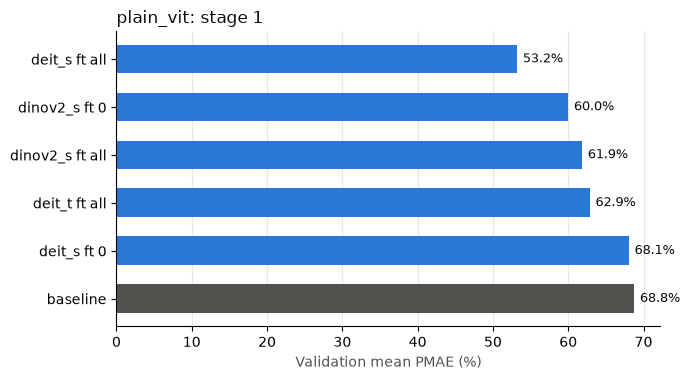

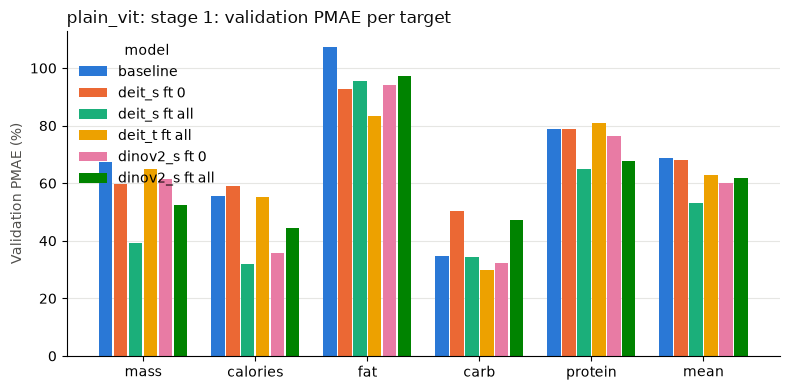

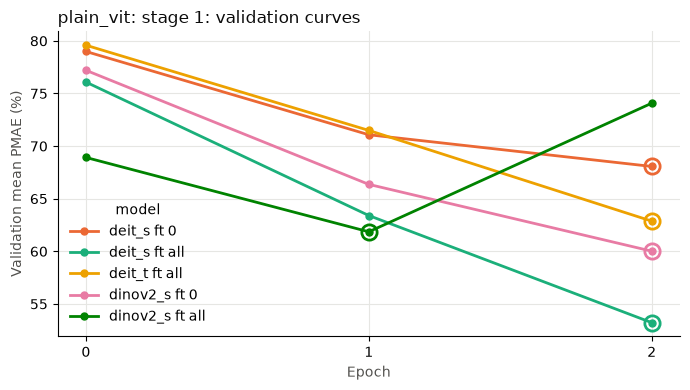

In [2]:
STAGE1 = dict(heads="single", hidden="512", image_size=224, backbone_lr=1e-4, seed=0)
stage1 = pd.concat([select(runs, unfreeze="all", **STAGE1), select(runs, unfreeze="0", **STAGE1).query("backbone in ['dinov2_s', 'deit_s']")]).sort_values("val_mean_pmae")
stage1 = stage1.assign(model=stage1["backbone"] + " ft " + stage1["unfreeze"])
compare(stage1, "model", f"{FAMILY}: stage 1", baseline=BASELINE)

### Etapa 1: coste computacional

- `params_M`: parámetros en millones (backbone, tronco y cabezas). `size_MB`: tamaño de `best.pt` (float32).
- `MMACs`: millones de multiplicaciones-acumulaciones por imagen a la resolución del run; no depende del hardware.
- `cpu_ms`: latencia mediana de una imagen (batch 1) en la CPU de esta máquina, con pesos aleatorios. Solo compara
  backbones entre sí en la misma máquina; la latencia que cuenta es la del dispositivo.
- `gpu_memory_gb` y `sec_per_epoch`: pico de memoria de GPU y segundos por época **del entrenamiento**.

/home/abello/Desktop/harness-thesis-multimodal-health-ai/code/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


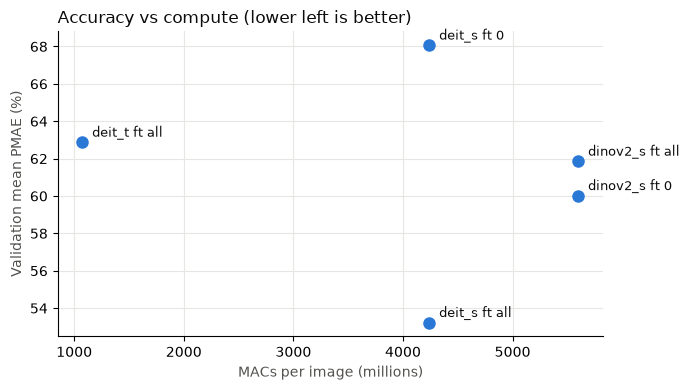

,family,val_mean_pmae,params_M,size_MB,MMACs,cpu_ms,gpu_memory_gb,sec_per_epoch,gpu
model,,,,,,,,,
deit_s ft all,plain_vit,53.225851,21.995397,88.033313,4241.163520,34.267572,NaN,13.266016,None
dinov2_s ft 0,plain_vit,60.018036,21.959685,87.896356,5600.118016,44.764316,NaN,16.143064,None
dinov2_s ft all,plain_vit,61.857766,21.959685,87.896356,5600.118016,49.662044,NaN,16.849267,None
deit_t ft all,plain_vit,62.873464,5.755845,23.074849,1074.889984,14.494526,NaN,7.898613,None
deit_s ft 0,plain_vit,68.068530,21.995397,88.033313,4241.163520,35.307153,NaN,13.000169,None


In [3]:
cost(stage1, "model")

## Etapa 2 (L2): ablaciones

Cada finalista sigue su propio camino greedy (mismos `BACKBONES` y `BEST_*` que en `02_experiments.ipynb`).
Cada paso compara el valor del factor dentro del backbone; menos de ~1 punto es empate.

In [4]:
BACKBONES = ("deit_t",)
BEST_UNFREEZE = {"deit_t": "all"}  # como texto, igual que en 02_experiments.ipynb

for backbone in BACKBONES:
    steps(runs, backbone, {
        "Step 1: fine-tuning depth": ("unfreeze", dict(heads="single", hidden="512", backbone_lr=1e-4, seed=0)),
        "Step 2: backbone learning rate": ("backbone_lr", dict(unfreeze=BEST_UNFREEZE[backbone], heads="single", hidden="512", seed=0)),
    })

deit_t - Step 1: fine-tuning depth
  nothing to compare yet
deit_t - Step 2: backbone learning rate
  nothing to compare yet


## Error por objetivo (test) de todas las ejecuciones terminadas

Ordenadas por validación. Solo se informa: no sirve para elegir.

In [5]:
target_table(runs[runs["status"] == "done"], "run", split="test")

## Evolución por objetivo de una ejecución

Comprueba si un objetivo empeora mientras la media mejora. La línea negra es la media; la vertical marca la época elegida.

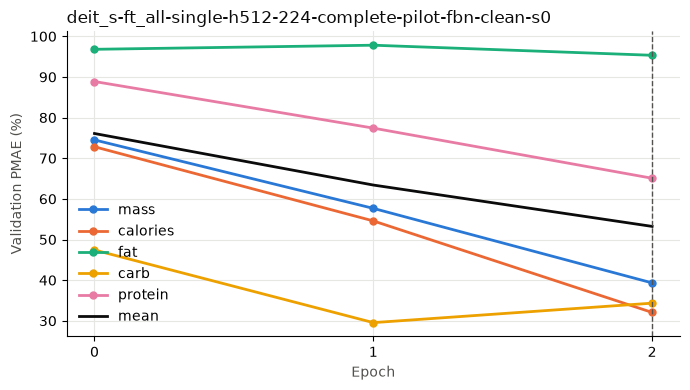

In [6]:
BEST = runs[runs["status"] == "done"].iloc[0]  # el mejor por validación; o all_runs[all_runs["run"] == "<nombre>"].iloc[0]
target_curves(BEST["path"])

## Etapa 3 (L3): media ± SD entre semillas

Una fila por configuración con más de una semilla; gráficas con el error de cada semilla (puntos) y la media ± SD.

In [7]:
seed_runs = seed_groups(runs)
if len(seed_runs):
    display(seed_table(seed_runs))
    seed_spread(seed_runs)
    seed_targets(seed_runs, "val")
    seed_targets(seed_runs, "test")
else:
    print("no configuration with more than one seed yet")

no configuration with more than one seed yet


## Métricas de test de los modelos finales

MAE, PMAE, RMSE y R² por objetivo, con la línea base como referencia. Por defecto, los tres mejores runs por
validación. Debajo, la media ± SD que escribe `train --all-seeds`.

In [8]:
FINAL = runs[runs["status"] == "done"].head(3)  # o select(runs, backbone=..., unfreeze=...)
test_metrics(FINAL, SPLIT).round(2)

unit     MAE  PMAE (%)    RMSE    R²
model                                              target                                        
deit_s-ft_all-single-h512-224-complete-pilot-fb... mass         g  120.75    104.88  133.88 -8.45
                                                   calories  kcal  119.56     43.76  145.19  0.13
                                                   fat          g   13.39     70.92   16.33 -0.13
                                                   carb         g    7.14     52.68    9.21 -0.80
                                                   protein      g    6.53     45.50    8.37  0.20
                                                   mean       NaN     NaN     63.55     NaN   NaN
dinov2_s-ft_0-single-h512-224-complete-pilot-fb... mass         g   42.77     37.15   47.16 -0.17
                                                   calories  kcal  133.69     48.93  157.39 -0.03
                                                   fat          g   14.53     76.96   18.31 -0.42
                                                   carb         g    5.80     42.78    7.24 -0.11
                                                   protein      g    7.80     54.31    9.99 -0.14
                                                   mean       NaN     NaN     52.03     NaN   NaN
dinov2_s-ft_all-single-h512-224-complete-pilot-... mass         g  117.06    101.68  128.85 -7.75
                                                   calories  kcal  129.39     47.36  160.11 -0.06
                                                   fat          g   13.21     69.95   15.62 -0.03
                                                   carb         g    9.70     71.59   11.97 -2.04
                                                   protein      g    7.11     49.48    9.15  0.04
                                                   mean       NaN     NaN     68.01     NaN   NaN
average baseline                                   mass         g   67.98     59.05   79.36 -2.32
                                                   calories  kcal  143.70     52.60  159.45 -0.05
                                                   fat          g   14.16     74.99   16.25 -0.12
                                                   carb         g    5.13     37.83    7.06 -0.06
                                                   protein      g    7.34     51.10    9.73 -0.09
                                                   mean       NaN     NaN     55.11     NaN   NaN

In [9]:
seed_files(FAMILY, SPLIT, MODE)

""


## Galería de platos de test

Los platos con menor error, los de mayor error y algunos al azar de un run, con su primer frame, el valor real y
el predicho. Necesita los frames en `data/`.

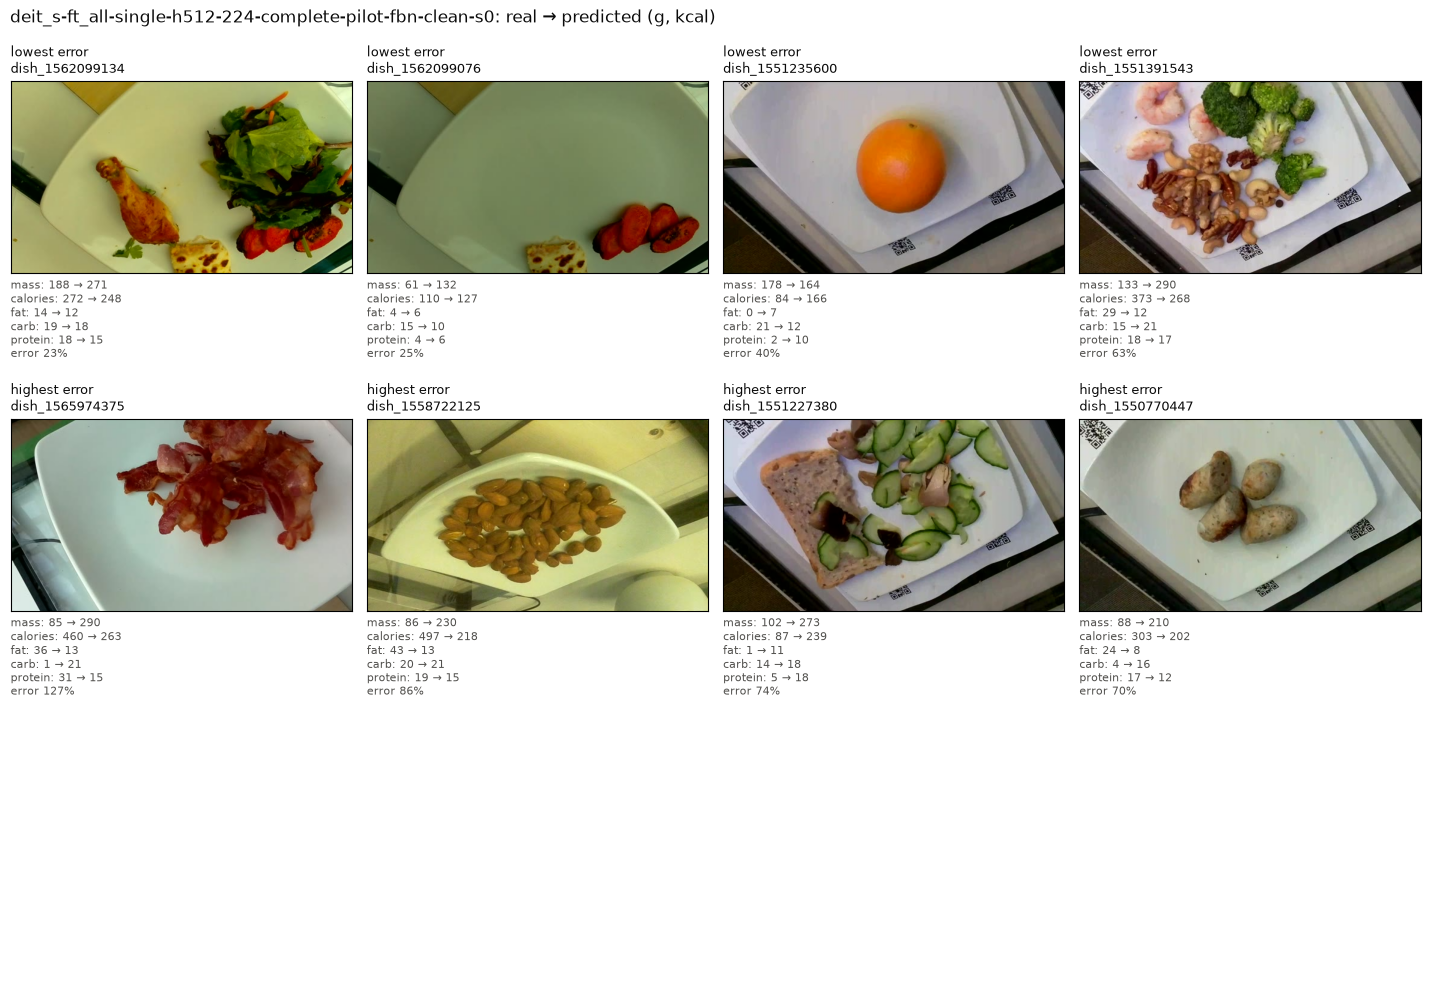

In [10]:
gallery(BEST["path"], SPLIT, MODE)